MÁSTER BIG DATA & DATA ENGINEERING

# Validación del paquete `traficFines`

Este cuaderno contiene **ejemplos e instrucciones para validar** que las clases del paquete funcionan
como pide el enunciado (ETAPA 2), incluidas las **excepciones** que deben lanzar:

| Módulo | Elementos validados |
| :-- | :-- |
| `traficFines.cache` | `Cache`, `CacheUrl`, `CacheError` |
| `traficFines.madridFines` | `MadridFines`, `MadridError`, `RAIZ` |

Cada comprobación usa `assert`: si una celda termina sin error, la comprobación ha pasado. Al final de cada
bloque se imprime una línea `✔` con lo validado.

## Instrucciones

1. **Instalar el paquete**, de una de estas dos formas:
   - Desde el fichero de la entrega: `pip install dist/traficfines-1.0.0-py3-none-any.whl` (más `pip install ipykernel` para poder ejecutar el cuaderno).
   - Desde el código, con [uv](https://docs.astral.sh/uv/): `uv sync` en la raíz del proyecto.
2. **Abrir este cuaderno** con el kernel del entorno donde se ha instalado el paquete.
3. **Ejecutar todas las celdas en orden** (*Run All*).

Organización del cuaderno:

- **Secciones 1 a 4**: no necesitan internet. Las descargas se **simulan** con `unittest.mock`, y la caché se crea en
  una carpeta temporal que se borra al final.
- **Sección 5**: usa el **portal real** de datos abiertos de Madrid. La primera ejecución descarga dos ficheros de
  unos 60 MB cada uno (1-2 minutos); las siguientes los leen de la caché (`~/.my_cache/validacion`).

## 0. Librerías y utilidades

In [1]:
import hashlib
import shutil
import tempfile
import time
from io import StringIO
from pathlib import Path
from unittest.mock import patch, Mock

import pandas as pd
from IPython.display import Image, display

import traficFines.cache as modulo_cache
from traficFines.cache import Cache, CacheUrl, CacheError, CACHE_DIR
from traficFines.madridFines import MadridFines, MadridError, RAIZ

`comprobar_excepcion` ejecuta una llamada que **debe fallar** y verifica que lanza exactamente la excepción
esperada. Si no lanza nada, o lanza otra distinta, la celda falla.

In [2]:
def comprobar_excepcion(excepcion, funcion, *args, **kwargs):
    """Comprueba que funcion(*args, **kwargs) lanza `excepcion` y muestra su mensaje."""
    try:
        funcion(*args, **kwargs)
    except excepcion as e:
        print(f"  ✔ {excepcion.__name__}: {e}")
        return e
    except Exception as e:
        raise AssertionError(f"Se esperaba {excepcion.__name__} y se obtuvo {type(e).__name__}: {e}")
    raise AssertionError(f"Se esperaba {excepcion.__name__} pero no se lanzó ninguna excepción")


def respuesta_simulada(contenido: bytes = b"contenido", status: int = 200) -> Mock:
    """Crea un objeto que imita la respuesta de requests.get."""
    return Mock(status_code=status, content=contenido)


# Carpeta temporal para las pruebas de caché de las secciones 1 a 4 (se borra al final).
# Cache lee la variable CACHE_DIR del módulo al crear cada objeto, así que basta con cambiarla aquí.
# Se restaura a su valor original (~/.my_cache) antes de la sección 5.
CACHE_DIR_ORIGINAL = CACHE_DIR
CARPETA_PRUEBAS = Path(tempfile.mkdtemp(prefix="validacion_traficFines_"))
modulo_cache.CACHE_DIR = CARPETA_PRUEBAS
print("CACHE_DIR original:     ", CACHE_DIR_ORIGINAL)
print("CACHE_DIR para pruebas: ", CARPETA_PRUEBAS)

CACHE_DIR original:      /Users/fmorera/.my_cache
CACHE_DIR para pruebas:  /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk


## 1. Clase `Cache`

Guarda y recupera datos en disco dentro de `CACHE_DIR / app_name`. Por defecto `CACHE_DIR` es `~/.my_cache`;
en las secciones 1 a 4 de este cuaderno apunta a la carpeta temporal.

### 1.1 Constructor y propiedades

In [3]:
cache = Cache("validacion", 7)
print("app_name:    ", cache.app_name)
print("obsolescence:", cache.obsolescence)
print("cache_dir:   ", cache.cache_dir)
print("(con la configuración por defecto sería", CACHE_DIR_ORIGINAL / "validacion", ")")

assert cache.app_name == "validacion"
assert cache.obsolescence == 7
# cache_dir es la ruta completa de la sub-carpeta de la aplicación: CACHE_DIR / app_name
assert cache.cache_dir == str(CARPETA_PRUEBAS / "validacion")
print("✔ Constructor y propiedades correctos")

app_name:     validacion
obsolescence: 7
cache_dir:    /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk/validacion
(con la configuración por defecto sería /Users/fmorera/.my_cache/validacion )
✔ Constructor y propiedades correctos


Los atributos son privados: `app_name`, `cache_dir` y `obsolescence` no tienen *setter*, así que no se pueden
modificar desde fuera (`AttributeError`).

In [4]:
comprobar_excepcion(AttributeError, setattr, cache, "app_name", "otro")
comprobar_excepcion(AttributeError, setattr, cache, "cache_dir", "/otra/carpeta")
comprobar_excepcion(AttributeError, setattr, cache, "obsolescence", 30)
print("✔ app_name, cache_dir y obsolescence son de solo lectura")

  ✔ AttributeError: property 'app_name' of 'Cache' object has no setter
  ✔ AttributeError: property 'cache_dir' of 'Cache' object has no setter
  ✔ AttributeError: property 'obsolescence' of 'Cache' object has no setter
✔ app_name, cache_dir y obsolescence son de solo lectura


### 1.2 Excepciones del constructor

In [5]:
print("app_name vacío, solo espacios o no string:")
comprobar_excepcion(CacheError, Cache, "", 7)
comprobar_excepcion(CacheError, Cache, "   ", 7)
comprobar_excepcion(CacheError, Cache, 123, 7)

print("obsolescence negativo o no entero:")
comprobar_excepcion(CacheError, Cache, "app", -1)
comprobar_excepcion(CacheError, Cache, "app", 1.5)
print("✔ Validaciones del constructor correctas")

app_name vacío, solo espacios o no string:
  ✔ CacheError: app_name debe ser un string no vacío
  ✔ CacheError: app_name debe ser un string no vacío
  ✔ CacheError: app_name debe ser un string no vacío
obsolescence negativo o no entero:
  ✔ CacheError: obsolescence debe ser un entero >= 0
  ✔ CacheError: obsolescence debe ser un entero >= 0
✔ Validaciones del constructor correctas


### 1.3 `set`, `exists` y `load`

In [6]:
assert not cache.exists("saludo")

cache.set("saludo", "Hola, Madrid. Año 2024: ñ, á, €")
assert cache.exists("saludo")
assert cache.load("saludo") == "Hola, Madrid. Año 2024: ñ, á, €"

# El fichero se guarda en CACHE_DIR / app_name / name
ruta = CARPETA_PRUEBAS / "validacion" / "saludo"
assert ruta.is_file()
print("Fichero creado en:", ruta)
print("Contenido:", cache.load("saludo"))
print("✔ set / exists / load correctos (incluidos caracteres especiales)")

Fichero creado en: /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk/validacion/saludo
Contenido: Hola, Madrid. Año 2024: ñ, á, €
✔ set / exists / load correctos (incluidos caracteres especiales)


`load` de un dato que no existe lanza `CacheError`:

In [7]:
comprobar_excepcion(CacheError, cache.load, "no_existe")

  ✔ CacheError: No existe ningún dato /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk/validacion/no_existe


traficFines.cache.CacheError('No existe ningún dato /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk/validacion/no_existe')

### 1.4 `how_old`: edad del dato en milisegundos

In [8]:
cache.set("reciente", "x")
time.sleep(0.2)
edad = cache.how_old("reciente")
print(f"Edad del dato: {edad:.0f} ms")
assert 200 <= edad < 5_000

comprobar_excepcion(CacheError, cache.how_old, "no_existe")
print("✔ how_old correcto")

Edad del dato: 204 ms
  ✔ CacheError: No existe dato /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk/validacion/no_existe
✔ how_old correcto


La caducidad se calcula comparando `how_old` con `obsolescence` (en días). Con `obsolescence=0` cualquier dato
está caducado; con 7 días, un dato recién guardado no lo está:

In [9]:
cache_0 = Cache("validacion", 0)
assert cache_0._esta_caducado("reciente") is True
assert cache._esta_caducado("reciente") is False
print("✔ Caducidad según obsolescence correcta")

✔ Caducidad según obsolescence correcta


### 1.5 `delete` y `clear`

In [10]:
cache.delete("reciente")
assert not cache.exists("reciente")
assert cache.exists("saludo")   # el resto de datos sigue en la caché
print("✔ delete borra solo el dato indicado")

# Según el enunciado, borrar un dato que no existe no lanza ninguna excepción.
cache.delete("no_existe")
print("✔ delete de un dato inexistente no lanza excepción")

✔ delete borra solo el dato indicado
✔ delete de un dato inexistente no lanza excepción


In [11]:
cache.set("a", "1")
cache.set("b", "2")
cache.clear()
assert not cache.exists("a") and not cache.exists("b") and not cache.exists("saludo")

# clear sobre una caché que aún no tiene carpeta no falla.
Cache("app_sin_carpeta", 1).clear()
print("✔ clear vacía la caché")

✔ clear vacía la caché


## 2. Clase `CacheUrl`

Hereda de `Cache` y guarda el contenido de URLs. El nombre del fichero es el **hash MD5** de la URL y de los
parámetros opcionales (`**kwargs`), de modo que URLs largas o con caracteres especiales dan nombres cortos y
seguros.

En esta sección `requests.get` se **simula** con `unittest.mock.patch`, así que no se accede a internet y se
puede contar cuántas descargas se hacen.

### 2.1 Nombre en la caché: hash de la URL y los parámetros

In [12]:
url = "https://agenciatributaria.madrid.es/portal/site/contribuyente"
print("MD5 de la URL (ejemplo del enunciado):", hashlib.md5(url.encode("utf-8")).hexdigest())

nombre_sin_params = CacheUrl._obtener_hash_completo(url, {})
nombre_con_params = CacheUrl._obtener_hash_completo(url, {"MES": 5})
print("Nombre sin parámetros:", nombre_sin_params)
print("Nombre con MES=5:     ", nombre_con_params)

assert len(nombre_sin_params) == 32 and nombre_sin_params.isalnum()
assert nombre_sin_params != nombre_con_params
# El orden de los parámetros no cambia el nombre.
assert CacheUrl._obtener_hash_completo(url, {"a": 1, "b": 2}) == CacheUrl._obtener_hash_completo(url, {"b": 2, "a": 1})
print("✔ Nombres de 32 caracteres, distintos según los parámetros e independientes de su orden")

MD5 de la URL (ejemplo del enunciado): 456cb7e307cb1e8bb1e31528b2f8478b
Nombre sin parámetros: aaedd4c984faa1d4ccbb16e3f9bad23f
Nombre con MES=5:      4529e9453ed044d4cd34b1ac78b84f16
✔ Nombres de 32 caracteres, distintos según los parámetros e independientes de su orden


### 2.2 `get`: descarga una sola vez y después usa la caché

In [13]:
cache_url = CacheUrl("validacion_url", 7)
url = "https://ejemplo.test/datos.csv"

with patch.object(modulo_cache.requests, "get", return_value=respuesta_simulada(b"A;B\n1;2")) as get_simulado:
    primera = cache_url.get(url)
    segunda = cache_url.get(url)

print("Contenido devuelto:", repr(primera))
print("Descargas realizadas:", get_simulado.call_count)
assert primera == segunda == "A;B\n1;2"
assert get_simulado.call_count == 1, "la segunda llamada debe leer de la caché"
print("✔ get descarga una vez y la segunda vez lee de la caché")

Contenido devuelto: 'A;B\n1;2'
Descargas realizadas: 1
✔ get descarga una vez y la segunda vez lee de la caché


Si el dato está **caducado** (`obsolescence=0`), `get` vuelve a descargarlo:

In [14]:
cache_url_0 = CacheUrl("validacion_url_0", 0)

with patch.object(modulo_cache.requests, "get", return_value=respuesta_simulada()) as get_simulado:
    cache_url_0.get(url)
    cache_url_0.get(url)

print("Descargas realizadas:", get_simulado.call_count)
assert get_simulado.call_count == 2
print("✔ Con obsolescence=0 se descarga cada vez")

Descargas realizadas: 2
✔ Con obsolescence=0 se descarga cada vez


Los ficheros del portal vienen en **Latin-1**; `get` los decodifica correctamente:

In [15]:
texto_latin1 = "ESTACIONAR CON AUTORIZACIÓN NO VÁLIDA".encode("latin-1")
with patch.object(modulo_cache.requests, "get", return_value=respuesta_simulada(texto_latin1)):
    texto = cache_url.get("https://ejemplo.test/latin1.csv")
print(texto)
assert texto == "ESTACIONAR CON AUTORIZACIÓN NO VÁLIDA"
print("✔ Decodificación Latin-1 correcta")

ESTACIONAR CON AUTORIZACIÓN NO VÁLIDA
✔ Decodificación Latin-1 correcta


### 2.3 Excepción si el servidor no responde con código 200

In [16]:
url_error = "https://ejemplo.test/no_existe.csv"
with patch.object(modulo_cache.requests, "get", return_value=respuesta_simulada(status=404)):
    comprobar_excepcion(CacheError, cache_url.get, url_error)

assert not cache_url.exists(url_error), "una respuesta errónea no debe guardarse"
print("✔ Error HTTP -> CacheError y no se guarda nada")

  ✔ CacheError: Se obtuvo error al tratar de obtener información de https://ejemplo.test/no_existe.csv, con código de estado 404
✔ Error HTTP -> CacheError y no se guarda nada


### 2.4 `exists`, `load`, `how_old` y `delete` reciben la URL (y los parámetros)

In [17]:
url = "https://ejemplo.test/multas.csv"
with patch.object(modulo_cache.requests, "get", return_value=respuesta_simulada(b"mayo")):
    cache_url.get(url, MES=5)

assert cache_url.exists(url, MES=5)
assert not cache_url.exists(url, MES=6)   # otros parámetros -> otro dato
assert not cache_url.exists(url)          # sin parámetros -> otro dato
assert cache_url.load(url, MES=5) == "mayo"
print(f"Edad: {cache_url.how_old(url, MES=5):.0f} ms")

cache_url.delete(url, MES=5)
assert not cache_url.exists(url, MES=5)
print("✔ exists / load / how_old / delete trabajan con la URL y sus parámetros")

Edad: 0 ms
✔ exists / load / how_old / delete trabajan con la URL y sus parámetros


In [18]:
print("Excepciones con una URL que no está en la caché:")
comprobar_excepcion(CacheError, cache_url.load, "https://ejemplo.test/nada")
comprobar_excepcion(CacheError, cache_url.how_old, "https://ejemplo.test/nada")

cache_url.delete("https://ejemplo.test/nada")   # no existe: no lanza excepción
print("  ✔ delete de una URL que no está en la caché no lanza excepción")

Excepciones con una URL que no está en la caché:
  ✔ CacheError: No existe ningún dato /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk/validacion_url/a77ad6c2b300f089d09003a3239204f6
  ✔ CacheError: No existe dato /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk/validacion_url/a77ad6c2b300f089d09003a3239204f6
  ✔ delete de una URL que no está en la caché no lanza excepción


## 3. Clase `MadridFines`: limpieza y carga (datos simulados)

Para validar `clean`, `load` y `add` sin internet se usa un **portal simulado** con tres meses de 2024
(enero a marzo) y cuatro multas por mes. Los CSV imitan los problemas de los ficheros reales: espacios sobrantes,
caracteres nulos en los nombres de columna y celdas vacías. Febrero usa la variante de columnas `COORDENADA_X/Y`.

In [19]:
CABECERA = ("CALIFICACION;LUGAR;MES;ANIO;HORA;IMP_BOL;DESCUENTO;PUNTOS;DENUNCIANTE;HECHO-BOL;"
            "VEL_LIMITE ;VEL_CIRCULA ;COORDENADA{s}X;COORDENADA{s}Y\x00\x00   \n")
MULTAS = [  # (calificación, hora HH.MM, importe, descuento)
    ("LEVE", "8.30", "60.0", "SI"),
    ("GRAVE", "8.59", "200.0", "SI"),
    ("MUY GRAVE", "20.05", "500.0", "NO"),
    ("LEVE", "0.00", "90.0", "SI"),
]

def csv_simulado(mes: int, anio: int) -> str:
    separador = "_" if mes == 2 else "-"
    lineas = [CABECERA.format(s=separador)]
    for calificacion, hora, importe, descuento in MULTAS:
        lineas.append(f"{calificacion}   ;CL ALCALA 1   ;{mes};{anio};{hora};{importe};{descuento} ;"
                      f"0;POLICIA  ;HECHO  ;50 ; ;  ;  \n")
    return "".join(lineas)

PORTAL_SIMULADO = {(mes, 2024): csv_simulado(mes, 2024) for mes in (1, 2, 3)}

def get_url_simulado(year, month):
    """Imita MadridFines.get_url: devuelve una 'URL' o MadridError si el mes no está publicado."""
    if (month, year) not in PORTAL_SIMULADO:
        raise MadridError(f"No se encontró el recurso para {month}/{year}")
    return f"simulado://{year}/{month}"

def nuevo_madrid_simulado() -> MadridFines:
    """MadridFines cuya caché devuelve los CSV del portal simulado."""
    multas = MadridFines("validacion_madrid", 7)
    multas.cacheurl.get = lambda url, **kw: PORTAL_SIMULADO[(int(url.split("/")[-1]), int(url.split("/")[-2]))]
    return multas

# Mientras dure la sección, get_url usa el portal simulado.
simulacion_get_url = patch.object(MadridFines, "get_url", staticmethod(get_url_simulado))
simulacion_get_url.start()
print(PORTAL_SIMULADO[(1, 2024)])

CALIFICACION;LUGAR;MES;ANIO;HORA;IMP_BOL;DESCUENTO;PUNTOS;DENUNCIANTE;HECHO-BOL;VEL_LIMITE ;VEL_CIRCULA ;COORDENADA-X;COORDENADA-Y     
LEVE   ;CL ALCALA 1   ;1;2024;8.30;60.0;SI ;0;POLICIA  ;HECHO  ;50 ; ;  ;  
GRAVE   ;CL ALCALA 1   ;1;2024;8.59;200.0;SI ;0;POLICIA  ;HECHO  ;50 ; ;  ;  
MUY GRAVE   ;CL ALCALA 1   ;1;2024;20.05;500.0;NO ;0;POLICIA  ;HECHO  ;50 ; ;  ;  
LEVE   ;CL ALCALA 1   ;1;2024;0.00;90.0;SI ;0;POLICIA  ;HECHO  ;50 ; ;  ;  



### 3.1 Constructor y propiedades

In [20]:
multas = nuevo_madrid_simulado()
assert isinstance(multas.cacheurl, CacheUrl)
assert multas.data.empty and multas.loaded == []
print("✔ Al crearse: data vacío y loaded == []")

print("data y loaded no se pueden reasignar desde fuera:")
comprobar_excepcion(AttributeError, setattr, multas, "data", pd.DataFrame())
comprobar_excepcion(AttributeError, setattr, multas, "loaded", [])

copia = multas.loaded
copia.append((1, 1999))
assert multas.loaded == [], "loaded debe devolver una copia"
print("✔ Modificar la lista devuelta por loaded no afecta al objeto")

print("Parámetros de caché inválidos:")
comprobar_excepcion(CacheError, MadridFines, "", 7)

✔ Al crearse: data vacío y loaded == []
data y loaded no se pueden reasignar desde fuera:
  ✔ AttributeError: property 'data' of 'MadridFines' object has no setter
  ✔ AttributeError: property 'loaded' of 'MadridFines' object has no setter
✔ Modificar la lista devuelta por loaded no afecta al objeto
Parámetros de caché inválidos:
  ✔ CacheError: app_name debe ser un string no vacío


traficFines.cache.CacheError('app_name debe ser un string no vacío')

### 3.2 `clean`: limpieza y normalización

In [21]:
df = pd.read_csv(StringIO(PORTAL_SIMULADO[(1, 2024)]), sep=";")
print("Columnas ANTES: ", list(df.columns))

resultado = MadridFines.clean(df)

print("Columnas DESPUÉS:", list(df.columns))
display(df)

assert resultado is None, "clean modifica df y no devuelve nada"
# 1. Nombres de columna sin espacios ni caracteres nulos
assert "VEL_LIMITE" in df.columns and "VEL_CIRCULA" in df.columns and "COORDENADA-Y" in df.columns
# 2. Valores de texto sin espacios
assert df["CALIFICACION"].tolist() == ["LEVE", "GRAVE", "MUY GRAVE", "LEVE"]
assert df["LUGAR"].iloc[0] == "CL ALCALA 1" and df["DESCUENTO"].iloc[0] == "SI"
# 3. Columnas numéricas (las celdas vacías pasan a NaN)
for columna in ["VEL_LIMITE", "VEL_CIRCULA", "COORDENADA-X", "COORDENADA-Y"]:
    assert pd.api.types.is_numeric_dtype(df[columna]), columna
assert df["VEL_CIRCULA"].isna().all()
# 4. Índice fecha a partir de ANIO, MES (día 1) y HORA en formato HH.MM
assert df.index.name == "fecha"
assert list(df.index) == list(pd.to_datetime(
    ["2024-01-01 08:30", "2024-01-01 08:59", "2024-01-01 20:05", "2024-01-01 00:00"]))
print("✔ clean normaliza columnas, textos, numéricos y crea el índice fecha")

Columnas ANTES:  ['CALIFICACION', 'LUGAR', 'MES', 'ANIO', 'HORA', 'IMP_BOL', 'DESCUENTO', 'PUNTOS', 'DENUNCIANTE', 'HECHO-BOL', 'VEL_LIMITE ', 'VEL_CIRCULA ', 'COORDENADA-X', 'COORDENADA-Y\x00\x00   ']
Columnas DESPUÉS: ['CALIFICACION', 'LUGAR', 'MES', 'ANIO', 'HORA', 'IMP_BOL', 'DESCUENTO', 'PUNTOS', 'DENUNCIANTE', 'HECHO-BOL', 'VEL_LIMITE', 'VEL_CIRCULA', 'COORDENADA-X', 'COORDENADA-Y']


,CALIFICACION,LUGAR,MES,ANIO,HORA,IMP_BOL,DESCUENTO,PUNTOS,DENUNCIANTE,HECHO-BOL,VEL_LIMITE,VEL_CIRCULA,COORDENADA-X,COORDENADA-Y
fecha,,,,,,,,,,,,,,
2024-01-01 08:30:00,LEVE,CL ALCALA 1,1,2024,8.30,60.0,SI,0,POLICIA,HECHO,50,NaN,NaN,NaN
2024-01-01 08:59:00,GRAVE,CL ALCALA 1,1,2024,8.59,200.0,SI,0,POLICIA,HECHO,50,NaN,NaN,NaN
2024-01-01 20:05:00,MUY GRAVE,CL ALCALA 1,1,2024,20.05,500.0,NO,0,POLICIA,HECHO,50,NaN,NaN,NaN
2024-01-01 00:00:00,LEVE,CL ALCALA 1,1,2024,0.00,90.0,SI,0,POLICIA,HECHO,50,NaN,NaN,NaN


✔ clean normaliza columnas, textos, numéricos y crea el índice fecha


La variante de columnas `COORDENADA_X` / `COORDENADA_Y` (febrero) también se convierte a número:

In [22]:
df_feb = pd.read_csv(StringIO(PORTAL_SIMULADO[(2, 2024)]), sep=";")
MadridFines.clean(df_feb)
assert pd.api.types.is_numeric_dtype(df_feb["COORDENADA_X"])
assert pd.api.types.is_numeric_dtype(df_feb["COORDENADA_Y"])
print("✔ Variante COORDENADA_X / COORDENADA_Y correcta")

✔ Variante COORDENADA_X / COORDENADA_Y correcta


### 3.3 `load`: descarga un mes o un año completo

In [23]:
df_ene = MadridFines.load(2024, 1, multas.cacheurl)
assert isinstance(df_ene, pd.DataFrame) and len(df_ene) == 4
print("✔ load(2024, 1) devuelve un DataFrame con", len(df_ene), "multas")

df_anio = MadridFines.load(2024, None, multas.cacheurl)
meses = sorted(int(m) for m in df_anio["MES"].unique())
assert meses == [1, 2, 3]
print("✔ load(2024, None) junta los meses publicados:", meses)

print("Mes o año no publicados:")
comprobar_excepcion(MadridError, MadridFines.load, 2024, 7, multas.cacheurl)
comprobar_excepcion(MadridError, MadridFines.load, 2030, None, multas.cacheurl)

✔ load(2024, 1) devuelve un DataFrame con 4 multas
✔ load(2024, None) junta los meses publicados: [1, 2, 3]
Mes o año no publicados:
  ✔ MadridError: No se encontró el recurso para 7/2024
  ✔ MadridError: No hay datos de ningún mes de 2030 en el portal.


traficFines.madridFines.MadridError('No hay datos de ningún mes de 2030 en el portal.')

### 3.4 `add`: añadir meses sin duplicar

In [24]:
multas = nuevo_madrid_simulado()
multas.add(2024, 1)
print("loaded:", multas.loaded, "| filas:", len(multas.data))
assert multas.loaded == [(1, 2024)] and len(multas.data) == 4

multas.add(2024, 1)   # ya cargado: no hace nada
assert multas.loaded == [(1, 2024)] and len(multas.data) == 4
print("✔ Añadir un mes ya cargado no duplica datos")

multas.add(2024, 3)
assert multas.loaded == [(1, 2024), (3, 2024)] and len(multas.data) == 8
print("✔ Se pueden acumular varios meses:", multas.loaded)

loaded: [(1, 2024)] | filas: 4
✔ Añadir un mes ya cargado no duplica datos
✔ Se pueden acumular varios meses: [(1, 2024), (3, 2024)]


Con `month=None` se añade el **año completo**. Los meses que ya estaban cargados sueltos no se duplican, y
`loaded` pasa a registrar `(None, año)`:

In [25]:
multas.add(2024)
print("loaded:", multas.loaded)
print("Multas por mes:", multas.data.groupby("MES").size().to_dict())
assert multas.loaded == [(None, 2024)]
assert multas.data.groupby("MES").size().to_dict() == {1: 4, 2: 4, 3: 4}

multas.add(2024, 2)   # incluido en el año completo
multas.add(2024)      # año ya cargado
assert len(multas.data) == 12
print("✔ Año completo sin duplicados")

loaded: [(None, 2024)]
Multas por mes: {1: 4, 2: 4, 3: 4}
✔ Año completo sin duplicados


In [26]:
print("Mes fuera de rango:")
comprobar_excepcion(ValueError, multas.add, 2024, 0)
comprobar_excepcion(ValueError, multas.add, 2024, 13)

print("Mes no publicado en el portal:")
comprobar_excepcion(MadridError, multas.add, 2023, 7)
assert multas.loaded == [(None, 2024)], "un error no debe modificar loaded"
print("✔ Los errores no modifican los datos cargados")

Mes fuera de rango:
  ✔ ValueError: Mes no válido: 0
  ✔ ValueError: Mes no válido: 13
Mes no publicado en el portal:
  ✔ MadridError: No se encontró el recurso para 7/2023
✔ Los errores no modifican los datos cargados


## 4. Análisis de datos (datos simulados)

Con los datos simulados se pueden calcular a mano los resultados esperados y compararlos con los de los métodos.

### 4.1 Sin datos cargados, los análisis lanzan `MadridError`

In [27]:
vacio = nuevo_madrid_simulado()
comprobar_excepcion(MadridError, vacio.fines_calificacion)
comprobar_excepcion(MadridError, vacio.total_payments)
comprobar_excepcion(MadridError, vacio.fines_hour, str(CARPETA_PRUEBAS / "vacio.png"))

  ✔ MadridError: No hay datos cargados. Usa add() antes de analizar.
  ✔ MadridError: No hay datos cargados. Usa add() antes de analizar.
  ✔ MadridError: No hay datos cargados. Usa add() antes de analizar.


traficFines.madridFines.MadridError('No hay datos cargados. Usa add() antes de analizar.')

### 4.2 `fines_calificacion`

In [28]:
multas = nuevo_madrid_simulado()
multas.add(2024, 1)
multas.add(2024, 3)

tabla = multas.fines_calificacion()
display(tabla)

# Cada mes simulado tiene 2 LEVE, 1 GRAVE y 1 MUY GRAVE.
assert tabla.index.names == ["MES", "ANIO"]
assert list(tabla.columns) == ["GRAVE", "LEVE", "MUY GRAVE"]
assert tabla.loc[(1, 2024)].tolist() == [1, 2, 1]
assert tabla.loc[(3, 2024)].tolist() == [1, 2, 1]
print("✔ Conteo por calificación, mes y año correcto")

,CALIFICACION,GRAVE,LEVE,MUY GRAVE
MES,ANIO,,,
1,2024,1,2,1
3,2024,1,2,1


✔ Conteo por calificación, mes y año correcto


### 4.3 `total_payments`

- **Importe máximo**: nadie paga con descuento → 60 + 200 + 500 + 90 = **850 €**.
- **Importe mínimo**: las multas con `DESCUENTO = "SI"` se pagan al 50 % → 30 + 100 + 500 + 45 = **675 €**.

In [29]:
importes = multas.total_payments()
display(importes)
assert importes.loc[(1, 2024), "IMPORTE_MAXIMO"] == 850
assert importes.loc[(1, 2024), "IMPORTE_MINIMO"] == 675
print("✔ Importes máximo y mínimo correctos")

,,IMPORTE_MAXIMO,IMPORTE_MINIMO
MES,ANIO,,
1,2024,850.0,675.0
3,2024,850.0,675.0


✔ Importes máximo y mínimo correctos


### 4.4 `fines_hour`

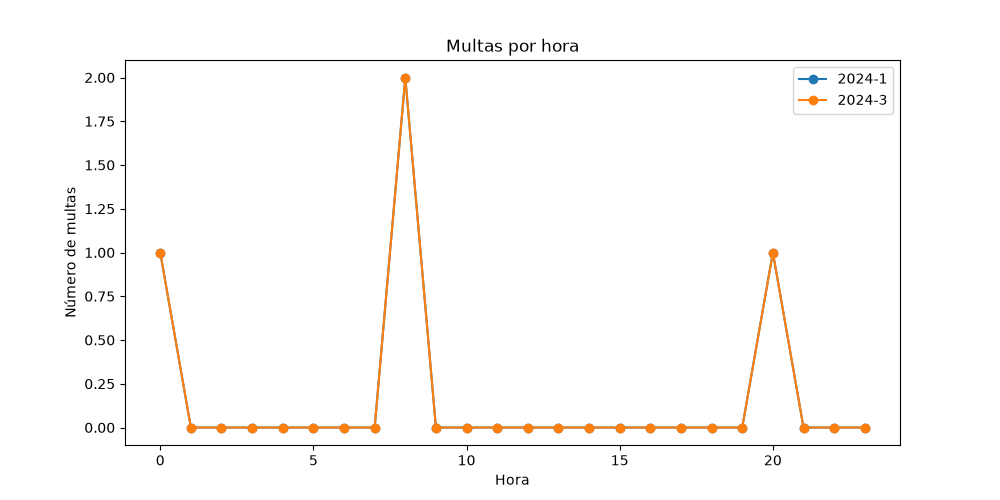

✔ Gráfico generado
Ruta en una carpeta que no existe:
  ✔ MadridError: No se pudo guardar el gráfico /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk/no_existe/grafico.png: [Errno 2] No such file or directory: '/var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk/no_existe/grafico.png'


traficFines.madridFines.MadridError("No se pudo guardar el gráfico /var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk/no_existe/grafico.png: [Errno 2] No such file or directory: '/var/folders/wl/h3081x91439_35yrzw1wh9hc0000gn/T/validacion_traficFines_milq13bk/no_existe/grafico.png'")

In [30]:
ruta_grafico = CARPETA_PRUEBAS / "multas_simuladas.png"
multas.fines_hour(str(ruta_grafico))
assert ruta_grafico.is_file()
display(Image(filename=ruta_grafico, width=600))
print("✔ Gráfico generado")

print("Ruta en una carpeta que no existe:")
comprobar_excepcion(MadridError, multas.fines_hour, str(CARPETA_PRUEBAS / "no_existe" / "grafico.png"))

### 4.5 `clean_cache`

In [31]:
multas.cacheurl.set("dato_temporal", "x")
multas.clean_cache()
assert not Cache.exists(multas.cacheurl, "dato_temporal")
print("✔ clean_cache vacía la caché")

# Fin de la simulación: get_url vuelve a consultar el portal real y la caché vuelve a ~/.my_cache.
simulacion_get_url.stop()
modulo_cache.CACHE_DIR = CACHE_DIR_ORIGINAL

✔ clean_cache vacía la caché


## 5. Validación con el portal real

Esta sección **requiere conexión a internet**. Usa la caché por defecto (`~/.my_cache/validacion`) con una
validez de 30 días, de modo que solo la primera ejecución descarga los ficheros.

### 5.1 `get_url`: localizar el CSV de un mes

In [32]:
print("RAIZ:", RAIZ)
for anio, mes in [(2017, 6), (2019, 5), (2023, 5), (2024, 12)]:
    url = MadridFines.get_url(anio, mes)
    print(f"{mes:>2}/{anio}: {url}")
    assert url.startswith(RAIZ) and url.endswith(".csv")
print("✔ get_url devuelve la URL absoluta del CSV Detalle")

RAIZ: https://datos.madrid.es/


 6/2017: https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/resource/210104-135-multas-circulacion-detalle-csv/download/210104-135-multas-circulacion-detalle-csv.csv


 5/2019: https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/resource/210104-91-multas-circulacion-detalle-csv/download/210104-91-multas-circulacion-detalle-csv.csv


 5/2023: https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/resource/210104-36-multas-circulacion-detalle-csv/download/210104-36-multas-circulacion-detalle-csv.csv


12/2024: https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/resource/210104-15-multas-circulacion-detalle-csv/download/210104-15-multas-circulacion-detalle-csv.csv
✔ get_url devuelve la URL absoluta del CSV Detalle


In [33]:
print("Meses no publicados (el portal empieza en 2014):")
comprobar_excepcion(MadridError, MadridFines.get_url, 2010, 1)
comprobar_excepcion(MadridError, MadridFines.get_url, 2050, 1)

Meses no publicados (el portal empieza en 2014):


  ✔ MadridError: No se encontró el recurso para Enero de 2010 en https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/downloads.


  ✔ MadridError: No se encontró el recurso para Enero de 2050 en https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/downloads.


traficFines.madridFines.MadridError('No se encontró el recurso para Enero de 2050 en https://datos.madrid.es/dataset/210104-0-multas-circulacion-detalle/downloads.')

### 5.2 Carga real y comparación con el enunciado

El enunciado muestra la tabla de `fines_calificacion` para mayo de varios años. Se cargan mayo de 2019 y de
2023 y se comprueba que las cifras coinciden exactamente.

In [34]:
real = MadridFines("validacion", 30)
print("Caché del portal real:", real.cacheurl.cache_dir)

inicio = time.time()
real.add(2019, 5)
real.add(2023, 5)
print(f"Carga: {time.time() - inicio:.1f} s | loaded: {real.loaded} | multas: {len(real.data):,}")

filas = len(real.data)
real.add(2023, 5)
assert len(real.data) == filas
print("✔ Añadir de nuevo mayo de 2023 no duplica datos")

Caché del portal real: /Users/fmorera/.my_cache/validacion


Carga: 20.2 s | loaded: [(5, 2019), (5, 2023)] | multas: 405,989
✔ Añadir de nuevo mayo de 2023 no duplica datos


In [35]:
calificacion = real.fines_calificacion()
display(calificacion)

ESPERADO = {  # tabla del enunciado
    (5, 2019): [61124, 111017, 747],
    (5, 2023): [137561, 94448, 1092],
}
for clave, valores in ESPERADO.items():
    assert calificacion.loc[clave, ["GRAVE", "LEVE", "MUY GRAVE"]].tolist() == valores, clave
print("✔ Las cifras coinciden con las del enunciado")

CALIFICACION   GRAVE    LEVE  MUY GRAVE
MES ANIO                               
5   2019       61124  111017        747
    2023      137561   94448       1092

✔ Las cifras coinciden con las del enunciado


In [36]:
importes = real.total_payments()
display(importes)
assert (importes["IMPORTE_MINIMO"] <= importes["IMPORTE_MAXIMO"]).all()
assert (importes["IMPORTE_MINIMO"] > 0).all()
print("✔ total_payments coherente (mínimo <= máximo)")

IMPORTE_MAXIMO  IMPORTE_MINIMO
MES ANIO                                
5   2019      17207760.0       8603880.0
    2023      30764540.0      15382270.0

✔ total_payments coherente (mínimo <= máximo)


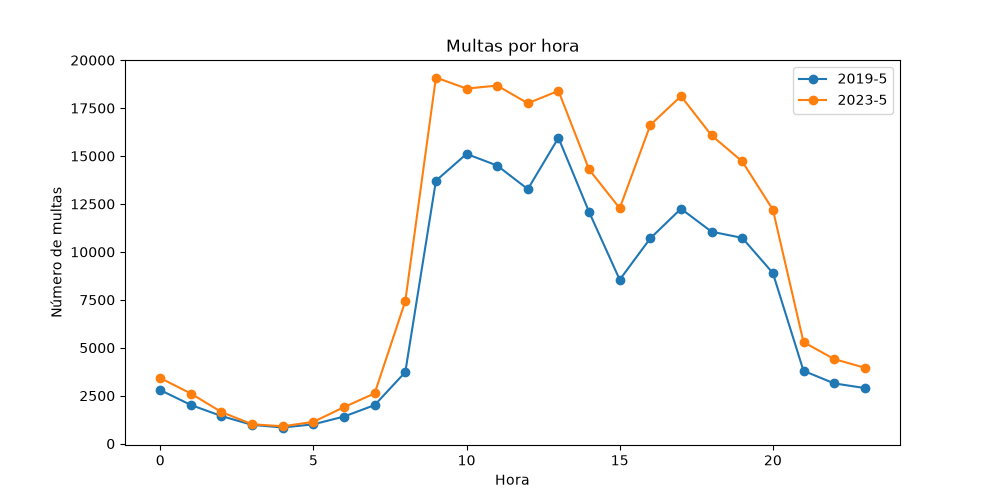

✔ Gráfico guardado en /Users/fmorera/Development/traficFines/cuadernos/evolucion_multas.png


In [37]:
ruta_real = Path("evolucion_multas.png")
real.fines_hour(str(ruta_real))
display(Image(filename=ruta_real, width=700))
print("✔ Gráfico guardado en", ruta_real.resolve())

## 6. Limpieza

Se borra la carpeta temporal de las secciones 1 a 4. La caché del portal real (`~/.my_cache/validacion`) se
conserva para que la siguiente ejecución sea rápida; para borrarla, descomentar la última línea.

In [38]:
shutil.rmtree(CARPETA_PRUEBAS, ignore_errors=True)
print("Carpeta temporal borrada:", not CARPETA_PRUEBAS.exists())

# real.clean_cache()   # borra también los CSV descargados del portal

Carpeta temporal borrada: True


---

*Este cuaderno se ha elaborado con ayuda de una herramienta de inteligencia artificial (Claude, de Anthropic).*